# Blur MIDI

Blur MIDI lays a MIDI file's notes out as a piano roll, time by pitch, and blurs it with Blur Core. Notes bleed into nearby pitches and moments through interference, and come back as new notes in the same MIDI format. (The API names it Blur Jazz.)

## Setup

In [1]:
import getpass
import os

from moth_atlas import Atlas

ENGINE = "blur-midi-staging"  # the engine this notebook runs: Atlas V2 (staging). Production: "blur-midi-v1"

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

client = Atlas()  # reads MOTH_API_KEY, and MOTH_API_BASE for which API to call

In [2]:
import io

import matplotlib.pyplot as plt
import numpy as np
import pretty_midi
from IPython.display import Audio, display


def upload(path):
    """A MIDI file as (name, bytes, type) for `files`: Python can't guess the type of a .mid file, and the engine
    only accepts audio/midi."""
    return (os.path.basename(path), open(path, "rb").read(), "audio/midi")


def midi(data):
    """A MIDI file (path or bytes) as a PrettyMIDI object."""
    return pretty_midi.PrettyMIDI(data if isinstance(data, str) else io.BytesIO(data))


def rolls(clips, play=True, seconds=20):
    """Draw {label: MIDI path or bytes} as piano rolls, one row each, then play each (sine voices, the first `seconds`)."""
    fig, axes = plt.subplots(len(clips), 1, figsize=(9, 1.8 * len(clips)), sharex=True, squeeze=False)
    for ax, (label, data) in zip(axes[:, 0], clips.items()):
        pm = midi(data)
        for i, inst in enumerate(pm.instruments):
            for n in inst.notes:
                ax.barh(n.pitch, n.end - n.start, left=n.start, height=0.8, color=f"C{i}", alpha=0.3 + 0.7 * n.velocity / 127)
        count = sum(len(inst.notes) for inst in pm.instruments)
        ax.set_ylabel(f"{label}\n{count} notes", rotation=0, ha="right", va="center")
    axes[-1, 0].set_xlabel("seconds")
    plt.show()
    if play:
        for label, data in clips.items():
            print(label)
            x = midi(data).synthesize(fs=22050)[: 22050 * seconds]
            display(Audio(0.9 * x / max(1e-9, np.abs(x).max()), rate=22050, normalize=False))

## Try it

`phrase.mid` is a short original phrase beside this notebook: a melody (track 1) over a bass line (track 2), 8 bars at 100 bpm. Point `midi` at your own file to try yours. The rolls below are drawn from the files; the audio is a plain sine rendering of the notes.

blur-midi-staging job 3073fe3f submitted
blur-midi-staging job 3073fe3f completed (3s)


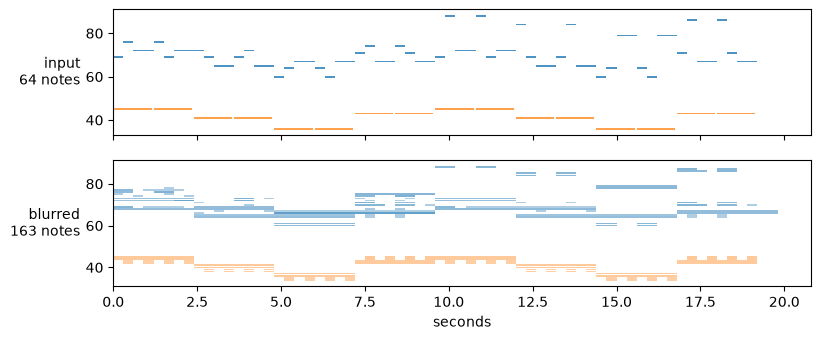

input


blurred


In [3]:
job = client.jobs.run(
    engine=ENGINE,
    params={
        "strength": 0.5,
        "reach": 0,
        "threshold": 0.1,
    },
    files={
        "midi": upload("phrase.mid"),
    },
)
rolls({"input": "phrase.mid", "blurred": job.output_bytes()})

## Parameters

What to expect from each:

- `strength` (0 to 1): 0 returns the notes unchanged; higher spreads each note further in pitch and time.
- `reach` (0 to 1): 0 mixes only neighbouring pitches and moments; 1 lets any pitch mix with any other.
- `threshold` (0 to 1): a noise gate. A change in velocity must exceed `threshold` × the loudest note to become a note, so lower values keep more of the faint bleed.
- `margin`: room above and below the played pitch range for the blur to spread into (default 0.15 of the span; 0 clips at the outer notes).
- `resolution`: MIDI ticks per piano-roll step. 0 picks it from the note lengths; larger is coarser and faster.
- `mask`: blur only some regions, as `[track, start_seconds, end_seconds]` lists. Everything else passes through.
- `qubits` (4 to 20): the qubit budget per pass; a roll bigger than that is tiled.

In [ ]:
# client.engines.get(ENGINE)  # its description, params, input and output files, from the API

## How it works

**Roll.** Each note track becomes a grid of velocities: one row per pitch (with `margin` added above and below), one column per `resolution` ticks.

**Blur.** The grid is blurred as Blur Core does it: amplitudes $\sqrt{v}$, Gray-coded rows and columns, one rotation per qubit, read back as probabilities. A note's velocity spreads to nearby pitches and steps, and interference makes some of those spots louder than others.

**Back to notes.** Wherever the blurred velocity rises by more than `threshold` × the roll's maximum, a note starts; where it falls, the note ends. The output keeps the input's MIDI type and tick resolution.

The blur is unitary before measurement, so information moves rather than disappears: low strengths keep the phrase recognisable and add ghost notes around it.

## Experiments

Each experiment changes one parameter and keeps the others fixed, and runs one job per value.

### Strength

Watch the note count: ghost notes appear around the phrase first, then the phrase itself dissolves.

strength=0.25
strength=0.5
strength=0.75
strength=1.0


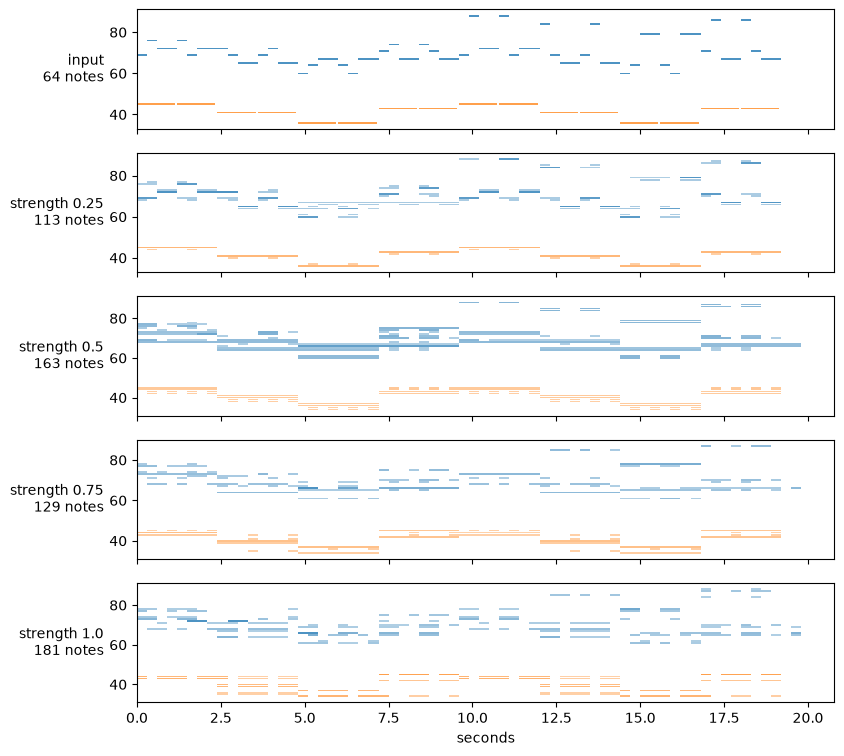

In [4]:
clips = {"input": "phrase.mid"}
for strength in (0.25, 0.5, 0.75, 1.0):
    print(f"strength={strength}")
    job = client.jobs.run(engine=ENGINE, params={"strength": strength}, files={"midi": upload("phrase.mid")}, quiet=True)
    clips[f"strength {strength}"] = job.output_bytes()
rolls(clips, play=False)

### Reach

At 0, notes bleed into neighbouring pitches. Towards 1, the blur jumps across the range, so new notes can land octaves away.

reach=0.0
reach=0.5
reach=1.0


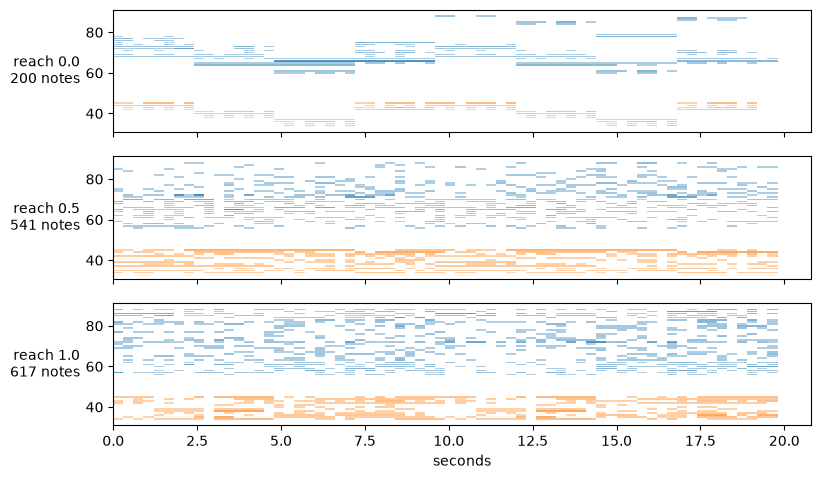

In [5]:
clips = {}
for reach in (0.0, 0.5, 1.0):
    print(f"reach={reach}")
    job = client.jobs.run(engine=ENGINE, params={"strength": 0.6, "reach": reach}, files={"midi": upload("phrase.mid")}, quiet=True)
    clips[f"reach {reach}"] = job.output_bytes()
rolls(clips, play=False)

### Threshold

The gate decides how much of the faint bleed turns into notes: low thresholds keep many quiet ghosts, high ones keep only the strongest.

threshold=0.03
threshold=0.1
threshold=0.3


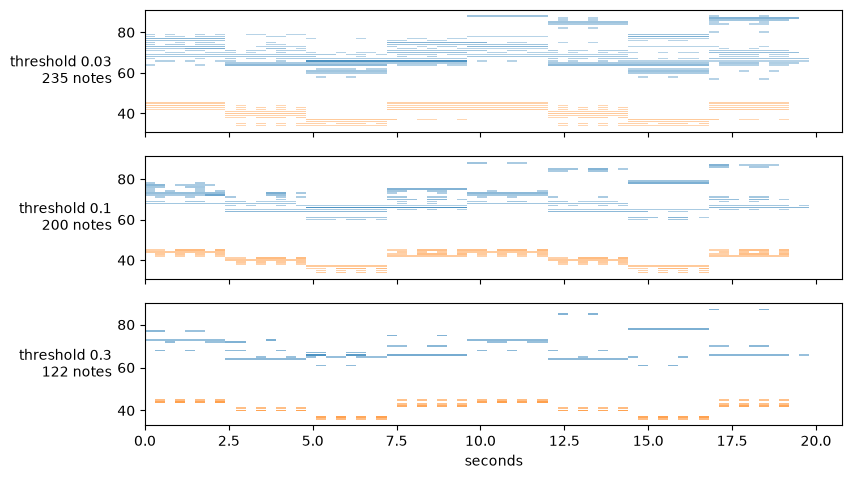

In [6]:
clips = {}
for threshold in (0.03, 0.1, 0.3):
    print(f"threshold={threshold}")
    job = client.jobs.run(engine=ENGINE, params={"strength": 0.6, "threshold": threshold}, files={"midi": upload("phrase.mid")}, quiet=True)
    clips[f"threshold {threshold}"] = job.output_bytes()
rolls(clips, play=False)

### Mask

Blur only the bass, and only in the second half (bars 5 to 8 start at 9.6 s). The melody and the first half come back untouched.

blur-midi-staging job 9d907849 submitted
blur-midi-staging job 9d907849 completed (2s)


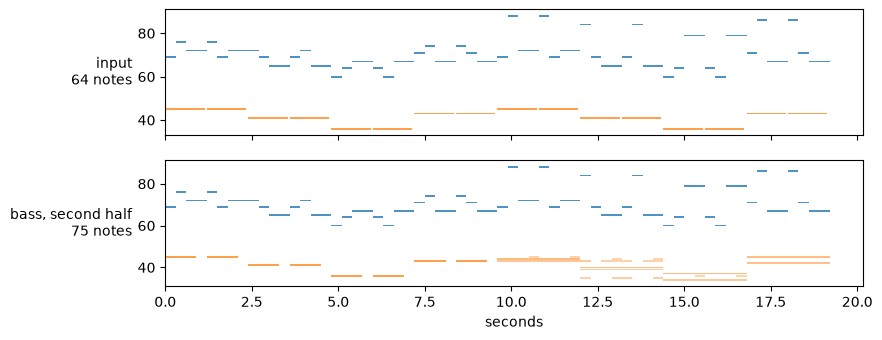

input


bass, second half


In [7]:
job = client.jobs.run(engine=ENGINE, params={"strength": 0.8, "mask": [[2, 9.6, 19.2]]}, files={"midi": upload("phrase.mid")})
rolls({"input": "phrase.mid", "bass, second half": job.output_bytes()})

## Questions

**Why are there more notes than I put in?**

The blur moves velocity into new pitch-time cells, and every cell that rises above the gate becomes a note. Raise `threshold` for fewer.

**Do drums work?**

Every note track is blurred, drums included, but a drum's pitch names an instrument, so spreading it in pitch swaps instruments rather than bending a note. Mask drum tracks out if you want them kept.

**Why does the sample play as sine tones?**

The notebook renders the notes with a plain sine voice so you can hear them here. Open the MIDI in any DAW to hear it with real instruments.

**Is this running on quantum hardware?**

No: on a statevector simulator, like Blur Core, so the same input and settings always give the same file.